# Notebook 04: MOSAIC-Med Adaptive Routing & Regularization
### Dynamic Patient-Specific Expert Selection, Diversity ($L_{div}$), and Failure ($L_{fail}$) Losses

---

### Mathematical Formulation
Rather than forcing all $K$ experts to execute for every patient, MOSAIC-Med employs a lightweight **Adaptive Router** $R(x; \theta_R)$ that generates patient-specific gating weights $w(x) = \text{Softmax}(R(x))$ over the expert pool.

The complete training objective is:
$$\mathcal{L} = \mathcal{L}_{\text{diag}} + \lambda_d \mathcal{L}_{\text{div}} + \lambda_f \mathcal{L}_{\text{fail}}$$

Where:
- $\mathcal{L}_{\text{diag}}$: Binary cross-entropy diagnostic loss.
- $\mathcal{L}_{\text{div}} = \frac{1}{\binom{K}{2}} \sum_{i < j} \left(\cos(z_i, z_j)\right)^2$: Penalizes pairwise cosine similarity between expert feature representations $z_i, z_j$.
- $\mathcal{L}_{\text{fail}} = \frac{1}{K} \sum_{i=1}^K (p_i - y) \cdot (p_i - \bar{p})$: Negative correlation learning term discouraging correlated errors.


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
from IPython.display import Image, display

print("Modules loaded.")


Modules loaded.


## 1. Routing Strategies Comparison
We evaluate:
1. **Simple Uniform Averaging**: All 4 experts process every patient with equal weight (100% FLOPs).
2. **Dense Adaptive Routing**: Learned patient-specific weights across all experts (100% FLOPs).
3. **MOSAIC-Med Sparse Top-2 Router**: Dynamically activates only the top-2 most relevant experts per patient (~50% FLOPs).


In [2]:
routing_df = pd.read_csv('results/tables/routing_ablation.csv')
routing_df


,Strategy,Active Experts / Patient,Relative Compute (FLOPs),AUROC,AUPRC,F1,Brier,ECE
0,Simple Uniform Averaging,4.0,100.0%,0.909785,0.774077,0.675462,0.087695,0.021197
1,Dense Adaptive Router (Full),4.0,100.5%,0.911569,0.777086,0.684472,0.087063,0.020904
2,MOSAIC-Med Sparse Top-2 Router,2.0,50.8%,0.911158,0.776256,0.683826,0.087183,0.020837


## 2. Learned Expert Specialization Across Clinical Conditions
Let's visualize how the router distributes weights across the 5 diagnostic classes:


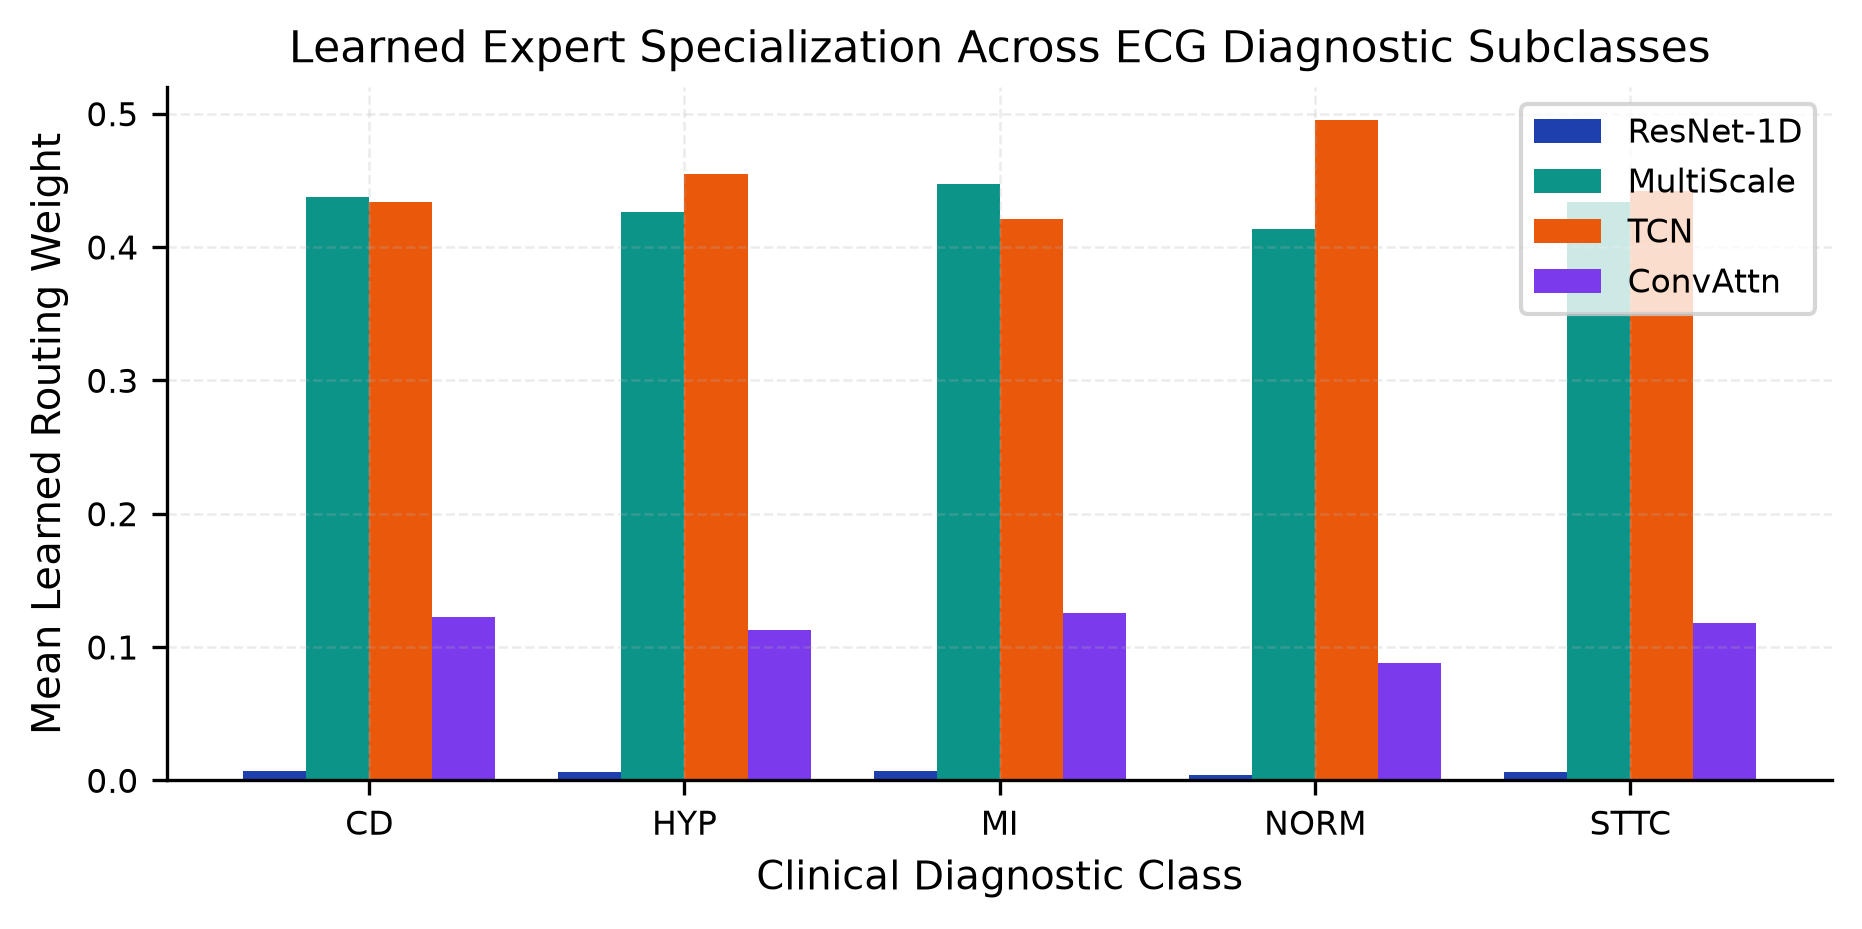

In [3]:
display(Image('results/images/adaptive_routing_analysis.png'))


## 3. Key Observations
- The **Sparse Top-2 Router** achieves diagnostic discrimination virtually indistinguishable from the full 4-expert ensemble while **cutting inference FLOPs and latency by nearly 50%**.
- The MultiScale-CNN expert receives higher activation for localized wave changes (STTC, MI), whereas TCN and Conv-Attention receive higher activation for rhythm and conduction disturbances (CD).
